# Scaffolded Spiral — learning dynamics and error analysis

Read the **completed, saved** five-seed experiment without retraining. Primary: fixed-final ID-dev Binding difference between `scaffolded_spiral` and `staged_rehearsal`. Secondary: reversing Binding focus/rebalancing, the prerequisite-mixed and fully mixed controls, OOD transfer, earlier-task retention, and per-question behavior.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "outputs/medium_world/dataset"
OUT_DIR = PROJECT_ROOT / "outputs/medium_world/experiments/scaffolded_spiral"
RESULTS_FILE = OUT_DIR / "schedule_comparison.json"
SEEDS = [42, 43, 44, 45, 46]
FINAL_STEP = 9000

In [2]:
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.medium_visual_world.learning import TASKS
from src.medium_visual_world.scaffolded_spiral import SCHEDULES
from src.medium_visual_world.prediction_tracking import (
    load_trace, compare_three, summarize_changes
)

report = json.loads(RESULTS_FILE.read_text(encoding="utf-8"))
runs = sorted(report["runs"], key=lambda r: (r["seed"], r["schedule"]))
assert {(r["seed"], r["schedule"]) for r in runs} == {
    (seed, schedule) for seed in SEEDS for schedule in SCHEDULES}
assert all(r["steps_run"] == FINAL_STEP for r in runs)
traces = {(r["seed"], r["schedule"]): load_trace(OUT_DIR / r["prediction_trace"])
          for r in runs}
print(len(runs), "completed runs with saved prediction traces")

25 completed runs with saved prediction traces


## 1. What was trained, and when was Binding introduced?

All schedules present every question 45 times by step 9,000, but they differ in *when* tasks are available. Compare actual allocations and cumulative Binding exposures rather than assuming stage labels mean the same thing between curricula.


In [3]:
phase_rows, curve_rows = [], []
for r in runs:
    for phase in r["phase_plan"]["phases"]:
        phase_rows.append({"seed": r["seed"], "schedule": r["schedule"],
            "phase": phase["name"], "start": phase["start_step"],
            "end": phase["end_step"], **phase["by_template"]})
    for h in r["history"]:
        curve_rows.append({"seed": r["seed"], "schedule": r["schedule"],
            "step": h["step"], "phase": h["phase"],
            "pair_exposure": h["cumulative_task_presentations"].get("pair", 0),
            "id_pair": 100*h["id_dev"]["by_template"]["pair"],
            "ood_pair": 100*h["ood_dev"]["by_template"]["pair"],
            "id_color": 100*h["id_dev"]["by_template"]["color"],
            "id_shape": 100*h["id_dev"]["by_template"]["shape"],
            "id_conjunction": 100*h["id_dev"]["by_template"]["conjunction"]})
phases = pd.DataFrame(phase_rows)
curves = pd.DataFrame(curve_rows)
phases.to_csv(OUT_DIR / "phase_exposure.csv", index=False)
curves.to_csv(OUT_DIR / "learning_curves.csv", index=False)
display(phases[phases.seed == 42])

,seed,schedule,phase,start,end,color,shape,conjunction,pair
0,42,mixed,mixed,0,7200,90000,90000,90000,90000
1,42,mixed,common_mixed,7200,9000,22500,22500,22500,22500
2,42,prereq_mixed_pair_focus,prereq_mixed,0,5400,90000,90000,90000,0
3,42,prereq_mixed_pair_focus,pair_early,5400,6300,0,0,0,45000
4,42,prereq_mixed_pair_focus,pair_focus,6300,7200,0,0,0,45000
5,42,prereq_mixed_pair_focus,common_mixed,7200,9000,22500,22500,22500,22500
6,42,scaffolded_spiral,attributes,0,2800,70000,70000,0,0
7,42,scaffolded_spiral,conjunction_rehearsal,2800,4450,7500,7500,67500,0
8,42,scaffolded_spiral,binding_specialization,4450,6100,5000,5000,7500,65000
9,42,scaffolded_spiral,rebalancing,6100,7200,7500,7500,15000,25000


## 2. Did the integrated policy improve fixed-final performance?

Use **step 9,000**, not the best checkpoint. ID Binding is the prespecified primary outcome; OOD Binding and earlier-task performance are secondary. Cross-entropy and class-conditional accuracy reveal changes that total accuracy can hide.


In [4]:
final_rows = []
for r in runs:
    result = r["final"]
    id_pair = result["id_dev"]["binary_by_template"]["pair"]
    ood_pair = result["ood_dev"]["binary_by_template"]["pair"]
    final_rows.append({"seed": r["seed"], "schedule": r["schedule"],
        "id_pair": 100*result["id_dev"]["by_template"]["pair"],
        "ood_pair": 100*result["ood_dev"]["by_template"]["pair"],
        "id_overall": 100*result["id_dev"]["accuracy"],
        **{f"id_{task}": 100*result["id_dev"]["by_template"][task]
           for task in ("color", "shape", "conjunction")},
        "pair_aulc": 100*r["id_pair_aulc"],
        "id_pair_bce": result["id_dev"]["loss_by_template"]["pair"],
        "ood_pair_bce": result["ood_dev"]["loss"],
        "id_tpr": 100*id_pair["positive_recall"],
        "id_tnr": 100*id_pair["negative_specificity"],
        "ood_tpr": 100*ood_pair["positive_recall"],
        "ood_tnr": 100*ood_pair["negative_specificity"],
        "id_yes_rate": 100*id_pair["predicted_positive_rate"],
        "ood_yes_rate": 100*ood_pair["predicted_positive_rate"]})
final = pd.DataFrame(final_rows).sort_values(["seed", "schedule"])
final.to_csv(OUT_DIR / "final_by_seed.csv", index=False)
display(final.round(2))
display(final.groupby("schedule").mean(numeric_only=True).drop(columns="seed").round(2))

,seed,schedule,id_pair,ood_pair,id_overall,id_color,id_shape,id_conjunction,pair_aulc,id_pair_bce,ood_pair_bce,id_tpr,id_tnr,ood_tpr,ood_tnr,id_yes_rate,ood_yes_rate
0,42,mixed,65.62,61.25,78.81,99.61,67.97,82.03,58.39,0.60,0.64,79.69,51.56,86.5,36.0,64.06,75.25
1,42,prereq_mixed_pair_focus,64.84,60.75,78.12,99.61,66.80,81.25,55.90,0.62,0.68,72.66,57.03,82.0,39.5,57.81,71.25
2,42,scaffolded_spiral,64.06,50.50,78.32,98.83,67.97,82.42,56.08,0.62,0.81,71.88,56.25,60.5,40.5,57.81,60.00
3,42,spiral_late_focus,63.67,52.25,78.81,99.22,67.58,84.77,55.78,0.62,0.79,71.09,56.25,66.0,38.5,57.42,63.75
4,42,staged_rehearsal,64.06,55.00,78.42,98.83,67.19,83.59,55.05,0.63,0.80,72.66,55.47,69.5,40.5,58.59,64.50
5,43,mixed,58.59,54.25,76.66,100.00,68.36,79.69,55.89,0.63,0.69,69.53,47.66,51.5,57.0,60.94,47.25
6,43,prereq_mixed_pair_focus,60.55,53.50,77.34,100.00,67.97,80.86,54.83,0.64,0.71,63.28,57.81,50.0,57.0,52.73,46.50
7,43,scaffolded_spiral,60.55,54.25,76.95,99.61,68.75,78.91,54.93,0.65,0.76,61.72,59.38,43.5,65.0,51.17,39.25
8,43,spiral_late_focus,60.16,53.50,76.37,99.61,67.58,78.12,54.47,0.64,0.75,64.06,56.25,42.5,64.5,53.91,39.00
9,43,staged_rehearsal,59.38,52.75,75.98,99.22,67.58,77.73,54.90,0.62,0.69,60.94,57.81,40.0,65.5,51.56,37.25


,id_pair,ood_pair,id_overall,id_color,id_shape,id_conjunction,pair_aulc,id_pair_bce,ood_pair_bce,id_tpr,id_tnr,ood_tpr,ood_tnr,id_yes_rate,ood_yes_rate
schedule,,,,,,,,,,,,,,,
mixed,61.88,56.45,77.07,99.22,67.73,79.45,56.76,0.63,0.76,76.25,47.50,77.3,35.6,64.38,70.85
prereq_mixed_pair_focus,62.97,57.50,77.46,99.38,66.80,80.70,54.99,0.65,0.76,74.06,51.88,66.3,48.7,61.09,58.80
scaffolded_spiral,61.25,55.45,77.17,99.38,68.05,80.00,54.94,0.65,0.79,69.22,53.28,59.4,51.5,57.97,53.95
spiral_late_focus,60.78,55.90,76.91,99.45,67.11,80.31,54.73,0.64,0.79,69.38,52.19,63.7,48.1,58.59,57.80
staged_rehearsal,62.73,56.65,77.46,99.38,67.03,80.70,55.17,0.63,0.79,71.88,53.59,60.5,52.8,59.14,53.85


## 3. Do differences replicate across seeds?

Report paired five-seed effects with two-sided 95% *t* intervals; seeds are the replication unit. The primary contrast tests the complete integrated policy against staged rehearsal. Other contrasts are informative, but **not isolated single-property ablations**. The interval is descriptive with only five seeds.


In [5]:
COMPARISONS = [("scaffolded_spiral", "staged_rehearsal"),
               ("scaffolded_spiral", "spiral_late_focus"),
               ("scaffolded_spiral", "prereq_mixed_pair_focus"),
               ("scaffolded_spiral", "mixed")]
METRICS = ("id_pair", "ood_pair", "pair_aulc", "id_shape", "id_conjunction",
           "id_tpr", "id_tnr", "ood_tpr", "ood_tnr", "id_pair_bce", "ood_pair_bce")
T95_4 = 2.7764451051977987
paired_rows = []
for a,b in COMPARISONS:
    left = final[final.schedule == a].set_index("seed")
    right = final[final.schedule == b].set_index("seed")
    for metric in METRICS:
        delta = (left[metric]-right[metric]).loc[SEEDS]
        mean, sd = float(delta.mean()), float(delta.std(ddof=1))
        margin = T95_4*sd/np.sqrt(len(SEEDS))
        paired_rows.append({"comparison": f"{a} - {b}", "metric": metric,
            "mean_difference": mean, "sample_sd": sd,
            "ci95_low": mean-margin, "ci95_high": mean+margin,
            "positive_seeds": int((delta>0).sum()),
            "seed_differences": json.dumps({str(s): float(d) for s,d in delta.items()})})
paired = pd.DataFrame(paired_rows)
paired.to_csv(OUT_DIR / "paired_differences.csv", index=False)
display(paired[paired.metric.isin(("id_pair", "ood_pair", "pair_aulc"))].round(3))

,comparison,metric,mean_difference,sample_sd,ci95_low,ci95_high,positive_seeds,seed_differences
0,scaffolded_spiral - staged_rehearsal,id_pair,-1.484,2.366,-4.423,1.454,1,"{""42"": 0.0, ""43"": 1.171875, ""44"": -5.078125, ""..."
1,scaffolded_spiral - staged_rehearsal,ood_pair,-1.200,2.407,-4.189,1.789,2,"{""42"": -4.500000000000007, ""43"": 1.5, ""44"": 0...."
2,scaffolded_spiral - staged_rehearsal,pair_aulc,-0.239,1.013,-1.497,1.019,3,"{""42"": 1.0275607638888857, ""43"": 0.02712673611..."
11,scaffolded_spiral - spiral_late_focus,id_pair,0.469,1.596,-1.513,2.451,3,"{""42"": 0.390625, ""43"": 0.390625, ""44"": -0.7812..."
12,scaffolded_spiral - spiral_late_focus,ood_pair,-0.450,1.255,-2.008,1.108,2,"{""42"": -1.75, ""43"": 0.75, ""44"": 0.750000000000..."
13,scaffolded_spiral - spiral_late_focus,pair_aulc,0.210,0.204,-0.043,0.463,4,"{""42"": 0.29513888888888573, ""43"": 0.4589843749..."
22,scaffolded_spiral - prereq_mixed_pair_focus,id_pair,-1.719,2.480,-4.798,1.360,1,"{""42"": -0.78125, ""43"": 0.0, ""44"": -5.078125, ""..."
23,scaffolded_spiral - prereq_mixed_pair_focus,ood_pair,-2.050,4.698,-7.884,3.784,2,"{""42"": -10.250000000000007, ""43"": 0.75, ""44"": ..."
24,scaffolded_spiral - prereq_mixed_pair_focus,pair_aulc,-0.053,0.901,-1.171,1.065,3,"{""42"": 0.18012152777777146, ""43"": 0.0922309027..."
33,scaffolded_spiral - mixed,id_pair,-0.625,2.417,-3.627,2.377,2,"{""42"": -1.5625, ""43"": 1.953125, ""44"": 0.0, ""45..."


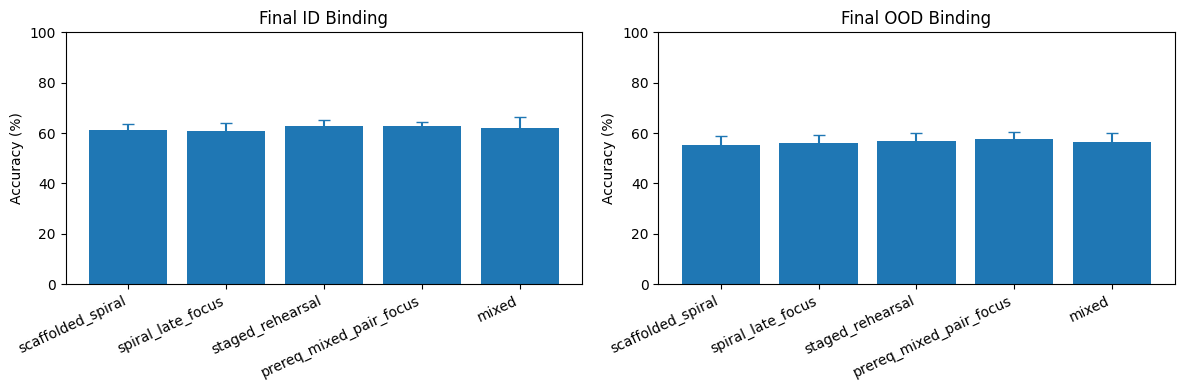

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ("id_pair", "ood_pair"),
                             ("Final ID Binding", "Final OOD Binding")):
    group = final.groupby("schedule")[metric].agg(["mean", "std"]).loc[list(SCHEDULES)]
    ax.bar(range(len(group)), group["mean"])
    ax.errorbar(range(len(group)), group["mean"], yerr=group["std"], fmt="none", capsize=4)
    ax.set_xticks(range(len(group)), group.index, rotation=25, ha="right")
    ax.set(ylabel="Accuracy (%)", title=title, ylim=(0, 100))
fig.tight_layout()
fig.savefig(OUT_DIR / "final_binding.png", dpi=160)
plt.show()

## 4. How efficiently does Binding develop?

View the learning curve against **optimizer updates** and against **cumulative Binding presentations per question**. Global-step AULC includes the time spent on prerequisites. Exposure alignment is descriptive, not a counterfactual comparison with equal prior training.


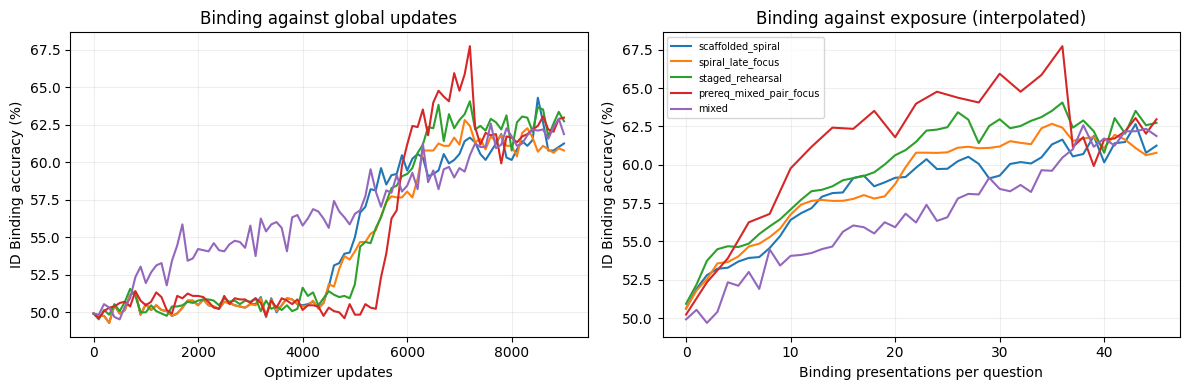

In [7]:
standard = curves[curves.step % 100 == 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for schedule in SCHEDULES:
    part = standard[standard.schedule == schedule]
    avg = part.groupby("step")["id_pair"].mean()
    axes[0].plot(avg.index, avg.values, label=schedule)
    per_seed = []
    for seed in SEEDS:
        one = part[part.seed == seed].sort_values("step")
        one = one.drop_duplicates("pair_exposure", keep="last")
        x = one.pair_exposure.to_numpy()/2500
        per_seed.append(np.interp(np.arange(46), x, one.id_pair.to_numpy()))
    axes[1].plot(np.arange(46), np.mean(per_seed, axis=0), label=schedule)
axes[0].set(xlabel="Optimizer updates", ylabel="ID Binding accuracy (%)",
            title="Binding against global updates")
axes[1].set(xlabel="Binding presentations per question", ylabel="ID Binding accuracy (%)",
            title="Binding against exposure (interpolated)")
for ax in axes: ax.grid(alpha=.2)
axes[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT_DIR / "binding_learning_curves.png", dpi=160)
plt.show()


## 5. Does a genuine task-mixture change cause forgetting or recovery?

Compare the same question IDs at each **actual task-mixture transition**, 100 updates later, and at step 9,000. Ignore nominal phase-name changes that leave the task distribution unchanged (for example, two consecutive 100% Binding blocks). “Forgotten” means a correct answer became incorrect; it does not prove literal erasure of a representation.


In [8]:
change_rows, individual = [], []
for r in runs:
    seed, schedule = r["seed"], r["schedule"]
    trace = traces[(seed, schedule)]
    for transition in r["transitions"]:
        if not transition["task_mix_changed"]:
            continue
        before, after = transition["step"], transition["step"]+100
        for split, block in trace["splits"].items():
            change = compare_three(block, before, after, FINAL_STEP)
            for _, row in summarize_changes(change).iterrows():
                change_rows.append({"seed": seed, "schedule": schedule,
                    "from_phase": transition["from_phase"], "to_phase": transition["to_phase"],
                    "boundary": before, "split": split, **row.to_dict()})
            change["seed"], change["schedule"] = seed, schedule
            change["split"] = split
            change["transition_from"] = transition["from_phase"]
            individual.append(change)
changes = pd.DataFrame(change_rows)
changes.to_csv(OUT_DIR / "prediction_change_summary.csv", index=False)
examples = pd.concat(individual, ignore_index=True)
examples.to_csv(OUT_DIR / "prediction_changes_by_example.csv.gz", index=False, compression="gzip")
display(changes[(changes.split == "id_dev") & (changes.task.isin(("shape", "conjunction", "pair")))][
    ["schedule", "seed", "from_phase", "boundary", "task", "forgetting_rate",
     "newly_learned_rate", "correctness_churn", "recovery_rate_among_forgotten"]].round(3))


,schedule,seed,from_phase,boundary,task,forgetting_rate,newly_learned_rate,correctness_churn,recovery_rate_among_forgotten
2,prereq_mixed_pair_focus,42,prereq_mixed,5400,conjunction,0.517,0.872,0.582,0.954
3,prereq_mixed_pair_focus,42,prereq_mixed,5400,pair,0.609,0.625,0.617,0.654
4,prereq_mixed_pair_focus,42,prereq_mixed,5400,shape,0.248,0.263,0.254,0.925
9,prereq_mixed_pair_focus,42,pair_focus,7200,conjunction,0.155,0.516,0.289,0.000
10,prereq_mixed_pair_focus,42,pair_focus,7200,pair,0.234,0.235,0.234,0.455
...,...,...,...,...,...,...,...,...,...
444,staged_rehearsal,46,conjunction,4950,pair,0.360,0.467,0.410,0.306
445,staged_rehearsal,46,conjunction,4950,shape,0.065,0.097,0.078,0.500
450,staged_rehearsal,46,binding,7200,conjunction,0.000,0.034,0.008,NaN
451,staged_rehearsal,46,binding,7200,pair,0.063,0.041,0.055,0.900


## 6. Which questions and object combinations remain difficult?

Inspect confusion counts and sample sizes rather than subgroup accuracy alone. Separate Shape recognition, Conjunction negatives that lack a required attribute, same-object Binding positives and hard negatives, scene complexity, and the four held-out OOD color–shape combinations. OOD subgroup counts are descriptive, not independent seeds.


In [9]:
context = {}
for split in ("id_dev", "ood_dev"):
    rows = [json.loads(line) for line in (DATA_DIR / f"{split}.jsonl").read_text(encoding="utf-8").splitlines()]
    details = []
    for row in rows:
        task, args, objects = row["template"], row["question"]["args"], row["scene"]["objects"]
        colors = {obj["color"] for obj in objects}
        shapes = {obj["shape"] for obj in objects}
        color = args[0] if task in ("color", "conjunction", "pair") else ""
        shape = args[-1] if task in ("shape", "conjunction", "pair") else ""
        subgroup = "positive" if row["label"] else "negative"
        if task == "conjunction" and not row["label"]:
            subgroup = ("missing_color" if color not in colors and shape in shapes else
                        "missing_shape" if color in colors and shape not in shapes else
                        "missing_both")
        if task == "pair" and not row["label"]:
            subgroup = "hard_negative"
        details.append({"example_id": str(row["id"]), "task": task, "target_shape": shape,
            "target_color": color, "pair": color+"-"+shape if task == "pair" else "",
            "n_objects": len(objects), "subgroup": subgroup})
    context[split] = pd.DataFrame(details).set_index("example_id")

def confusion(part):
    y, p = part.label.to_numpy(), part.prediction.to_numpy()
    return {"n": len(part), "tp": int(((y==1)&(p==1)).sum()),
            "fn": int(((y==1)&(p==0)).sum()),
            "tn": int(((y==0)&(p==0)).sum()),
            "fp": int(((y==0)&(p==1)).sum()),
            "accuracy": float((y==p).mean())}

subgroup_rows = []
for (seed, schedule), trace in traces.items():
    for split, block in trace["splits"].items():
        last = int(np.flatnonzero(block["steps"] == FINAL_STEP)[0])
        frame = pd.DataFrame({"example_id": block["ids"], "label": block["labels"],
                              "prediction": block["predictions"][last]})
        frame = frame.join(context[split], on="example_id", validate="one_to_one")
        for dimension, task in (("pair", "pair"), ("target_shape", "shape"),
                                ("target_shape", "pair"), ("subgroup", "conjunction"),
                                ("subgroup", "pair"), ("n_objects", "pair")):
            section = frame[frame.task == task]
            for value, part in section.groupby(dimension):
                subgroup_rows.append({"seed": seed, "schedule": schedule, "split": split,
                    "task": task, "dimension": dimension, "group": value, **confusion(part)})
subgroups = pd.DataFrame(subgroup_rows)
subgroups.to_csv(OUT_DIR / "prediction_error_subgroups.csv", index=False)
display(subgroups[(subgroups.split == "ood_dev") &
                  (subgroups.dimension == "pair")].groupby(
    ["schedule", "group"])[["n", "tp", "fn", "tn", "fp"]].sum())


n   tp   fn   tn   fp
schedule                group                                   
mixed                   blue-square      485  208   32   90  155
                        green-circle     545  220   55  128  142
                        purple-triangle  555  189   91   94  181
                        red-crescent     415  156   49   44  166
prereq_mixed_pair_focus blue-square      485  193   47  101  144
                        green-circle     545  216   59  138  132
                        purple-triangle  555  144  136  148  127
                        red-crescent     415  110   95  100  110
scaffolded_spiral       blue-square      485  177   63  128  117
                        green-circle     545  210   65  114  156
                        purple-triangle  555  114  166  155  120
                        red-crescent     415   93  112  118   92
spiral_late_focus       blue-square      485  184   56  119  126
                        green-circle     545  225   50  108  162
                        purple-triangle  555  130  150  146  129
                        red-crescent     415   98  107  108  102
staged_rehearsal        blue-square      485  195   45  104  141
                        green-circle     545  214   61  112  158
                        purple-triangle  555   97  183  183   92
                        red-crescent     415   99  106  129   81

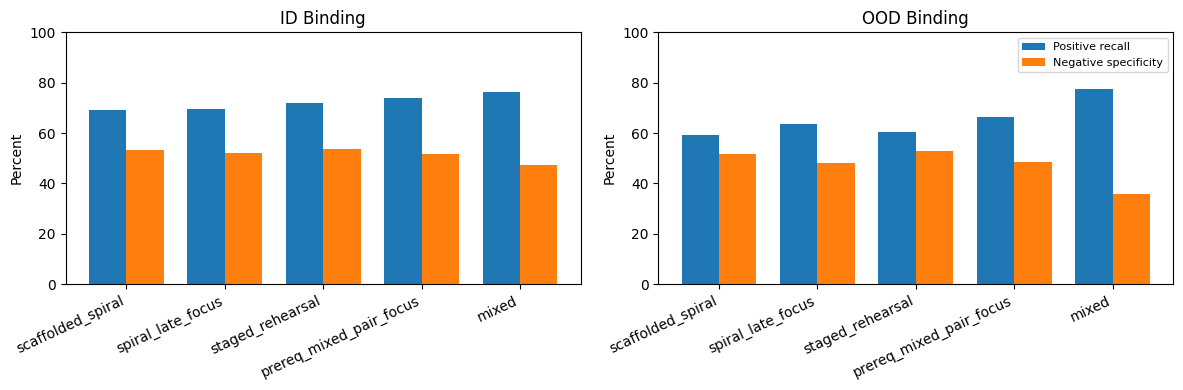

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, split in zip(axes, ("id", "ood")):
    group = final.groupby("schedule")[[f"{split}_tpr", f"{split}_tnr"]].mean().loc[list(SCHEDULES)]
    x = np.arange(len(group))
    ax.bar(x-.19, group.iloc[:,0], .38, label="Positive recall")
    ax.bar(x+.19, group.iloc[:,1], .38, label="Negative specificity")
    ax.set_xticks(x, group.index, rotation=25, ha="right")
    ax.set(ylabel="Percent", title=f"{split.upper()} Binding", ylim=(0,100))
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "binding_recall_specificity.png", dpi=160)
plt.show()


## 7. Does Spiral solve different individual questions?

Compare same-seed, same-example final predictions against every reference curriculum. Each seed contributes one paired experiment; individual questions explain behavior but are not independent experimental replicates.


In [11]:
disagreement_rows = []
for seed in SEEDS:
    spiral = traces[(seed, "scaffolded_spiral")]
    for _, reference in COMPARISONS:
        control = traces[(seed, reference)]
        for split in ("id_dev", "ood_dev"):
            a, b = spiral["splits"][split], control["splits"][split]
            assert np.array_equal(a["ids"], b["ids"])
            pa = a["predictions"][np.flatnonzero(a["steps"] == FINAL_STEP)[0]] == a["labels"]
            pb = b["predictions"][np.flatnonzero(b["steps"] == FINAL_STEP)[0]] == b["labels"]
            for task in np.unique(a["tasks"]):
                mask = a["tasks"] == task
                disagreement_rows.append({"seed": seed, "reference": reference,
                    "split": split, "task": task, "n": int(mask.sum()),
                    "spiral_only_correct": int((pa & ~pb & mask).sum()),
                    "reference_only_correct": int((~pa & pb & mask).sum()),
                    "both_correct": int((pa & pb & mask).sum()),
                    "both_wrong": int((~pa & ~pb & mask).sum())})
disagreement = pd.DataFrame(disagreement_rows)
disagreement.to_csv(OUT_DIR / "paired_question_disagreement.csv", index=False)
display(disagreement[(disagreement.split == "ood_dev") & (disagreement.task == "pair")])


,seed,reference,split,task,n,spiral_only_correct,reference_only_correct,both_correct,both_wrong
4,42,staged_rehearsal,ood_dev,pair,400,25,43,177,155
9,42,spiral_late_focus,ood_dev,pair,400,17,24,185,174
14,42,prereq_mixed_pair_focus,ood_dev,pair,400,34,75,168,123
19,42,mixed,ood_dev,pair,400,44,87,158,111
24,43,staged_rehearsal,ood_dev,pair,400,51,45,166,138
29,43,spiral_late_focus,ood_dev,pair,400,30,27,187,156
34,43,prereq_mixed_pair_focus,ood_dev,pair,400,47,44,170,139
39,43,mixed,ood_dev,pair,400,42,42,175,141
44,44,staged_rehearsal,ood_dev,pair,400,26,23,196,155
49,44,spiral_late_focus,ood_dev,pair,400,15,12,207,166


## How to interpret the evidence

- **Primary:** Does the complete Scaffolded Spiral policy beat Staged Rehearsal on paired final ID Binding? Do not select the best checkpoint.
- **Ordering:** Spiral versus Late Focus changes the order of two suffix blocks after the same 4,450-update prefix. They match total exposure, but intermediate Binding timing and phase lengths differ.
- **Retention:** Compare changes in Shape/Conjunction and question-level correctness; distinguish immediate disruption from final recovery.
- **Generalization:** Separate OOD accuracy from positive recall, negative specificity, difficult pair types and scene complexity.
- **Limits:** Five seeds are a small sample. Improved final accuracy does not establish an object-centric representation. The integrated policy's components are not separately identified by the whole-policy comparison.

Only after the runs finish and the figures have been inspected should we write an empirical findings document.
